# Mini-Project 2 – Solar Micro-Grid Dispatch Planner

**OOP with Python, Assignment 1 (Advent 2026)** · Wesonga John Collins

A rural health centre in Kasese runs a micro-grid. Each day the energy drawn from solar panels ($x$) and
batteries ($y$) must satisfy two demand constraints:

$$3x + 2y = D_1 \quad\text{(daytime load, kWh)}, \qquad 4x + y = D_2 \quad\text{(critical-equipment load, kWh)}$$

Reusable logic lives in `src/a1/microgrid.py` (classes `MicroGrid` and `HybridMicroGrid`) and is unit-tested
in `tests/test_microgrid.py`.

## 0. Setup

In [1]:
from pathlib import Path
import statistics
import timeit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from a1.microgrid import (
    HybridMicroGrid,
    MicroGrid,
    generate_demand,
    load_demand_csv,
    read_demands_interactive,
    save_demand_csv,
)

SEED = 2026                     # one seed for every random step in this notebook
N_DAYS = 30
N_DRAWS = 1000                  # Monte Carlo draws for the sensitivity analysis
INTERACTIVE = False             # set True to type demands yourself (keep False for Restart & Run All)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CSV_PATH = ROOT / "data" / "microgrid_demand.csv"
pd.set_option("display.precision", 2)

## 1. Task 1 – the `MicroGrid` class and whether the system is well-posed

Written as $A\mathbf{s} = \mathbf{d}$ with $A = \begin{pmatrix}3 & 2\\ 4 & 1\end{pmatrix}$,
$\mathbf{s} = (x, y)$, $\mathbf{d} = (D_1, D_2)$.

* **Determinant.** $\det A = 3\cdot1 - 2\cdot4 = -5 \neq 0$, so $A$ is invertible and every pair of demands has
  exactly one solution: $x = (2D_2 - D_1)/5$, $y = (4D_1 - 3D_2)/5$. A zero determinant would mean the two
  constraints were parallel (no solution, or infinitely many).
* **Condition number.** $\kappa(A) = \sigma_{\max}/\sigma_{\min}$ bounds how much a relative error in the
  demands can be amplified in the solution: $\|\Delta\mathbf{s}\|/\|\mathbf{s}\| \le \kappa(A)\,\|\Delta\mathbf{d}\|/\|\mathbf{d}\|$.
  Values near 1 are ideal; very large values (say $10^{8}$ and above) signal an ill-posed system.
* **Physical feasibility** is a separate question: the solution is unique, but it is only usable if
  $x \ge 0$ and $y \ge 0$, i.e. $D_1/2 \le D_2 \le 4D_1/3$.

In [2]:
grid = MicroGrid()
print(grid)
print(f"determinant = {grid.determinant():.4f}")
print(f"condition number = {grid.condition_number():.4f}  (exact value 3 + 2*sqrt(2) = {3 + 2 * np.sqrt(2):.4f})")
print("rank =", grid.rank(), "| well-posed:", grid.is_well_posed())

# Hand check for one day: D1 = 100, D2 = 120 -> x = 28, y = 8
print("solve_day(100, 120) =", grid.solve_day(100, 120))
assert np.allclose(grid.solve_day(100, 120), [28, 8])

MicroGrid(sources=('solar', 'battery'), det=-5, cond=5.83)
determinant = -5.0000
condition number = 5.8284  (exact value 3 + 2*sqrt(2) = 5.8284)
rank = 2 | well-posed: True
solve_day(100, 120) = [28.  8.]


The determinant is −5, so the system always has exactly one solution, and the condition number is 3 + 2√2 ≈ 5.83: a 1 % relative error in the demands can change the solution by at most about 5.8 % (in the 2-norm sense). That is small, so the system is well-posed and numerically safe to solve. Well-posedness does not guarantee a usable answer, however: the unique solution can still require negative energy, which happens whenever D2 falls outside the range D1/2 to 4D1/3 (Task 4). The hand check (D1 = 100, D2 = 120 gives x = 28, y = 8 kWh) matches the solver.

## 2. Task 2 – two input modes

**(a) Interactive input.** `read_demands_interactive` prompts for $D_1$ and $D_2$ and re-prompts on empty,
non-numeric or negative input. Because `input()` would block *Restart & Run All*, the function accepts a
replacement input function; below it is driven by a scripted sequence of answers that includes three bad ones.
Set `INTERACTIVE = True` in the setup cell to type values yourself.

In [3]:
if INTERACTIVE:
    d1, d2 = read_demands_interactive()
else:
    scripted = iter(["", "forty", "-12", "100", "120"])
    def fake_input(prompt):
        answer = next(scripted)
        print(f"{prompt}{answer!r}")
        return answer
    d1, d2 = read_demands_interactive(input_fn=fake_input)

print(f"\nAccepted D1 = {d1} kWh, D2 = {d2} kWh -> solar, battery =", grid.solve_day(d1, d2))

D1 daytime load (kWh): ''
  Invalid: empty input. Please try again.
D1 daytime load (kWh): 'forty'
  Invalid: 'forty' is not a number. Please try again.
D1 daytime load (kWh): '-12'
  Invalid: demand cannot be negative. Please try again.
D1 daytime load (kWh): '100'
D2 critical load (kWh): '120'

Accepted D1 = 100.0 kWh, D2 = 120.0 kWh -> solar, battery = [28.  8.]


**(b) 30 days from a CSV file.** The CSV is generated here with a seeded generator and saved to
`data/microgrid_demand.csv`, then read back. Assumptions (illustrative): daytime load about 100 kWh on weekdays
and 15 % lower at weekends (fewer outpatients), the critical-equipment load about 1.2 × the daytime load, and
independent Gaussian noise (sd 4 kWh) on each. Day 1 is a Monday.

In [4]:
demand_df = generate_demand(N_DAYS, rng=np.random.default_rng(SEED))
save_demand_csv(demand_df, CSV_PATH)
D = load_demand_csv(CSV_PATH)                  # 2 x 30 array: rows D1, D2
print("Loaded", D.shape, "from", CSV_PATH.relative_to(ROOT))
display(demand_df.head(8))
demand_df[["D1_kWh", "D2_kWh"]].describe().T

Loaded (2, 30) from data\microgrid_demand.csv


,day,weekday,D1_kWh,D2_kWh
0,1,Mon,96.8,111.5
1,2,Tue,101.0,126.6
2,3,Wed,92.4,114.2
3,4,Thu,105.6,131.3
4,5,Fri,102.6,119.5
5,6,Sat,83.8,103.3
6,7,Sun,83.8,98.4
7,8,Mon,101.2,119.6


,count,mean,std,min,25%,50%,75%,max
D1_kWh,30.0,95.99,8.01,79.5,90.90,99.10,101.88,107.3
D2_kWh,30.0,117.05,9.58,97.4,110.07,119.55,123.25,131.3


## 3. Task 3 – loop versus one vectorised call

Both use `scipy.linalg.solve`; the vectorised version passes the whole $2\times30$ right-hand side at once.

In [5]:
S_loop = grid.solve_loop(D)
S = grid.solve_all(D)
assert np.allclose(S_loop, S) and np.allclose(grid.A @ S, D)      # same answer, and it satisfies A s = d

n_calls = 200
t_loop = min(timeit.repeat(lambda: grid.solve_loop(D), number=n_calls, repeat=5)) / n_calls
t_vec = min(timeit.repeat(lambda: grid.solve_all(D), number=n_calls, repeat=5)) / n_calls
print(f"Python loop (30 solves): {t_loop * 1e6:8.1f} µs per 30-day run")
print(f"Vectorised (1 solve):    {t_vec * 1e6:8.1f} µs per 30-day run")
print(f"The vectorised call is about {t_loop / t_vec:.0f} times faster on this machine.")

Python loop (30 solves):   2258.0 µs per 30-day run
Vectorised (1 solve):       363.7 µs per 30-day run
The vectorised call is about 6 times faster on this machine.


*Timings depend on the computer; the ratio printed above is what matters.* Each `scipy.linalg.solve` call has a
fixed overhead (input checking, an LU factorisation of $A$, Python-to-LAPACK calls). The loop pays it 30 times
and factorises the same matrix 30 times; the vectorised call factorises $A$ once and back-substitutes all 30
right-hand sides inside compiled code. For 30 days both are fast, but the gap grows with the number of days.

## 4. Task 4 – physically infeasible days

A day is infeasible when the unique solution needs negative energy from a source. Strategy chosen:
**flag and report, then dispatch with non-negative least squares** (`scipy.optimize.nnls`), which finds the
non-negative $(x, y)$ that satisfies the two constraints as closely as possible. Clipping negatives to zero is
shown for comparison.

In [6]:
flags = grid.infeasible(S)
days = np.arange(1, N_DAYS + 1)
print(f"Infeasible days: {flags.sum()} of {N_DAYS} -> day(s) {days[flags].tolist()}")

S_nnls, residual = grid.solve_nonnegative(D)
S_clip = grid.clip_negative(S)

rows = []
for j in np.where(flags)[0]:
    rows.append({
        "day": days[j], "D1": D[0, j], "D2": D[1, j],
        "exact x": S[0, j], "exact y": S[1, j],
        "nnls x": S_nnls[0, j], "nnls y": S_nnls[1, j],
        "nnls unmet (kWh, norm)": residual[j],
        "clip unmet (kWh, norm)": np.linalg.norm(grid.A @ S_clip[:, j] - D[:, j]),
    })
pd.DataFrame(rows).set_index("day")

Infeasible days: 1 of 30 -> day(s) [20]


,D1,D2,exact x,exact y,nnls x,nnls y,"nnls unmet (kWh, norm)","clip unmet (kWh, norm)"
day,,,,,,,,
20,79.5,108.0,27.3,-1.2,26.82,0.0,1.2,2.68


Only day 20 (a Saturday) is infeasible: its demands (D1 = 79.5, D2 = 108.0 kWh) give y = −1.2 kWh, because the critical load is high relative to the daytime load (D2 exceeds 4D1/3 = 106.0). NNLS dispatches 26.8 kWh of solar and no battery, leaving an unmet residual of 1.2 kWh; clipping keeps x = 27.3 and sets y = 0, which leaves 2.7 kWh unmet. NNLS is therefore the better strategy: it re-optimises the remaining source rather than simply deleting the negative part. Physically, a negative battery value would mean charging the battery, which this model does not allow; in practice the centre would curtail non-critical load or accept a small shortfall on such days. The rule D1/2 ≤ D2 ≤ 4D1/3 lets the operator flag these days in advance.

## 5. Task 5 – statistics of solar and battery use

Computed with the `statistics` module on the dispatch plan (`nnls` solution, all values non-negative).

In [7]:
plan = pd.DataFrame({"solar_kWh": S_nnls[0], "battery_kWh": S_nnls[1]}, index=pd.Index(days, name="day"))
rows = {}
for source in plan:
    v = plan[source].tolist()
    rows[source] = {"mean": statistics.mean(v), "variance": statistics.variance(v),
                    "stdev": statistics.stdev(v), "CV (%)": statistics.stdev(v) / statistics.mean(v) * 100,
                    "min": min(v), "max": max(v)}
usage_stats = pd.DataFrame(rows).T
usage_stats

,mean,variance,stdev,CV (%),min,max
solar_kWh,27.6,6.26,2.50,9.06,22.42,31.94
battery_kWh,6.6,7.45,2.73,41.33,0.00,10.54


Solar supplies most of the energy (mean 27.6 kWh a day) and the battery much less (6.6 kWh). In absolute terms the two vary by similar amounts (standard deviations 2.5 and 2.7 kWh), but relative to its mean the battery is far more volatile: its coefficient of variation is 41 % against 9 % for solar, and it ranges from 0 to 10.5 kWh. The battery absorbs the day-to-day mismatch between the two loads: y = (4D1 − 3D2)/5 is the difference of two large, noisy numbers, so small changes in demand become large relative swings. The CV is the fairer comparison because the two sources operate at very different scales (the variances, in kWh², are less intuitive).

## 6. Task 6 – energy cost

Illustrative tariffs: solar UGX 150/kWh, battery UGX 450/kWh. Daily cost $= 150x + 450y$; monthly cost is the
total over the 30 days.

In [8]:
plan["cost_UGX"] = grid.daily_cost(S_nnls)
monthly = plan["cost_UGX"].sum()
print(f"Monthly (30-day) cost: UGX {monthly:,.0f}")
print(f"Mean daily cost:       UGX {plan['cost_UGX'].mean():,.0f}  "
      f"(range {plan['cost_UGX'].min():,.0f} - {plan['cost_UGX'].max():,.0f})")
share = (plan["battery_kWh"] * 450).sum() / monthly * 100
print(f"Battery share of cost: {share:.1f} %  vs share of energy: "
      f"{plan['battery_kWh'].sum() / (plan['solar_kWh'].sum() + plan['battery_kWh'].sum()) * 100:.1f} %")
# Hand check for day 1
assert np.isclose(plan["cost_UGX"].iloc[0], 150 * plan["solar_kWh"].iloc[0] + 450 * plan["battery_kWh"].iloc[0])
plan.round(2).head(10)

Monthly (30-day) cost: UGX 213,375
Mean daily cost:       UGX 7,112  (range 4,023 - 8,763)
Battery share of cost: 41.8 %  vs share of energy: 19.3 %


,solar_kWh,battery_kWh,cost_UGX
day,,,
1,25.24,10.54,8529.0
2,30.44,4.84,6744.0
3,27.20,5.40,6510.0
4,31.40,5.70,7275.0
5,27.28,10.38,8763.0
6,24.56,5.06,5961.0
7,22.60,8.00,6990.0
8,27.60,9.20,8280.0
9,28.50,6.70,7290.0


## 7. Task 7 – daily solar and battery use with daily cost

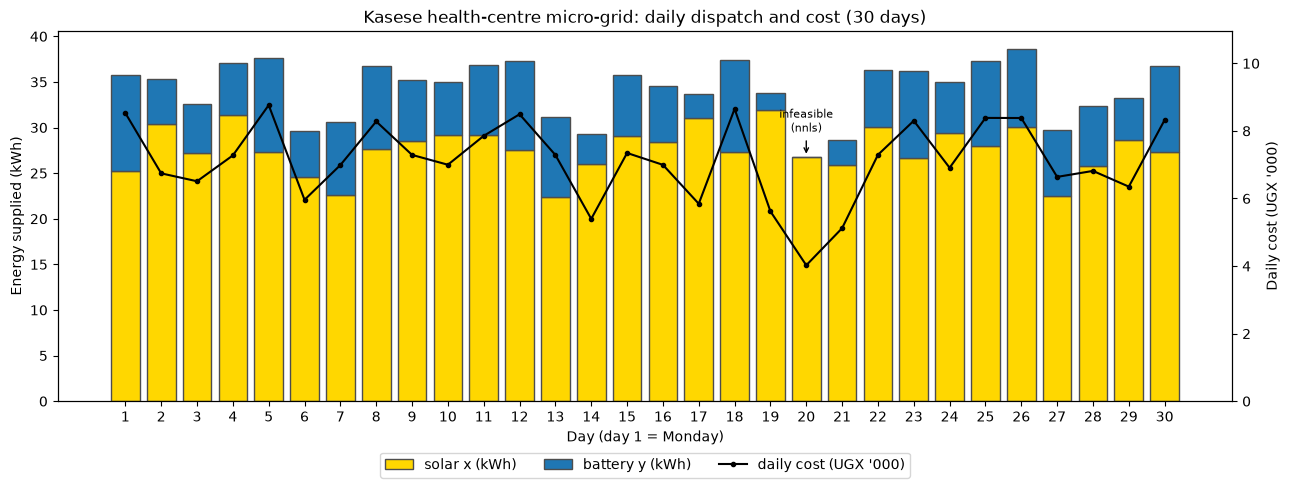

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(days, plan["solar_kWh"], color="gold", edgecolor="0.3", label="solar x (kWh)")
ax.bar(days, plan["battery_kWh"], bottom=plan["solar_kWh"], color="tab:blue", edgecolor="0.3",
       label="battery y (kWh)")
for j in np.where(flags)[0]:
    ax.annotate("infeasible\n(nnls)", (days[j], plan.iloc[j, :2].sum()), xytext=(0, 18),
                textcoords="offset points", ha="center", fontsize=8, arrowprops={"arrowstyle": "->"})
ax.set_xlabel("Day (day 1 = Monday)")
ax.set_ylabel("Energy supplied (kWh)")
ax.set_xticks(days)

ax2 = ax.twinx()
ax2.plot(days, plan["cost_UGX"] / 1000, "k.-", label="daily cost (UGX '000)")
ax2.set_ylabel("Daily cost (UGX '000)")
ax2.set_ylim(0, plan["cost_UGX"].max() / 1000 * 1.25)

handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
ax.set_title("Kasese health-centre micro-grid: daily dispatch and cost (30 days)")
fig.tight_layout()
plt.show()

The 30-day cost is UGX 213,375, an average of UGX 7,112 a day (range 4,023–8,763). Although the battery provides only 19 % of the energy, it accounts for 42 % of the cost because it is three times as expensive per kWh, so the daily cost line in the chart follows the height of the blue battery segment rather than the total bar. The cheapest day is the infeasible day 20, when no battery is used. Weekend loads are about 15 % lower by assumption, but the daily cost depends more on the split between sources than on total demand.

## 8. Extension – adding a diesel generator (`HybridMicroGrid`)

Third source: diesel $z$ (illustrative cost UGX 1,200/kWh). Chosen constraints: diesel contributes
one-for-one to both existing loads, and a new **night load** $D_3$ must be met by battery and diesel only
(solar is unavailable at night):

$$3x + 2y + z = D_1,\qquad 4x + y + z = D_2,\qquad y + z = D_3$$

$D_3$ is simulated (seeded) as 15 % of the daytime load plus noise.

In [10]:
hybrid = HybridMicroGrid()
print(hybrid, "| rank", hybrid.rank())
rng = np.random.default_rng(SEED + 1)
D3 = np.round(0.15 * D[0] + rng.normal(0, 1.0, N_DAYS), 1)
D_h = np.vstack([D, D3])

S_h = hybrid.solve_all(D_h)
flags_h = hybrid.infeasible(S_h)
S_h_plan, res_h = hybrid.solve_nonnegative(D_h)
print(f"Hybrid infeasible days: {flags_h.sum()} -> {days[flags_h].tolist()} (dispatched with nnls)")
hybrid_summary = pd.DataFrame(S_h_plan.T, columns=["solar", "battery", "diesel"]).describe().T[["mean", "std", "min", "max"]]
print(f"Hybrid monthly cost: UGX {hybrid.daily_cost(S_h_plan).sum():,.0f}")
hybrid_summary

HybridMicroGrid(sources=('solar', 'battery', 'diesel'), det=-4, cond=11.8) | rank 3
Hybrid infeasible days: 3 -> [17, 19, 20] (dispatched with nnls)
Hybrid monthly cost: UGX 517,042


,mean,std,min,max
solar,25.70,2.21,21.3,29.40
battery,4.84,2.96,0.0,9.52
diesel,9.33,2.67,4.6,13.82


**What if the new equation is linearly dependent on the others?** Suppose the third constraint were the sum of
the first two: $7x + 3y + 2z = D_1 + D_2$. It adds no new information.

In [11]:
dependent = HybridMicroGrid(coefficients=[[3, 2, 1], [4, 1, 1], [7, 3, 2]])
print(f"rank = {dependent.rank()} of 3, det = {dependent.determinant():.2e}, "
      f"cond = {dependent.condition_number():.2e}, dependent rows: {dependent.dependent_rows()}")
try:
    dependent.solve_day(100, 120, 220)
except np.linalg.LinAlgError as err:
    print("solve_day refused:", err)

# Consistent right-hand side (D3 = D1 + D2): infinitely many solutions; lstsq returns the minimum-norm one.
s_min, *_ = np.linalg.lstsq(dependent.A, [100, 120, 220], rcond=None)
print("consistent case, minimum-norm solution:", np.round(s_min, 3),
      "| check A s =", np.round(dependent.A @ s_min, 6))
s_other = s_min + 5 * np.array([1, 1, -5])        # (1, 1, -5) lies in the null space of A
print("another exact solution:", np.round(s_other, 3), "| check A s =", np.round(dependent.A @ s_other, 6))
# Inconsistent right-hand side (D3 != D1 + D2): no exact solution at all.
s_ls, res, *_ = np.linalg.lstsq(dependent.A, [100, 120, 200], rcond=None)
print("inconsistent case, best fit A s =", np.round(dependent.A @ s_ls, 3), "(target [100, 120, 200])")

rank = 2 of 3, det = 0.00e+00, cond = 1.92e+17, dependent rows: True
solve_day refused: system is singular or ill-conditioned (rank 2 of 3)
consistent case, minimum-norm solution: [26.667  6.667  6.667] | check A s = [100. 120. 220.]
another exact solution: [ 31.667  11.667 -18.333] | check A s = [100. 120. 220.]
inconsistent case, best fit A s = [ 93.333 113.333 206.667] (target [100, 120, 200])


With the diesel generator and the night-load constraint the 3 × 3 system is still well-posed (det = −4, condition number 11.8, rank 3), so `HybridMicroGrid` solves it with the methods inherited from `MicroGrid`. Three days (17, 19 and 20) are infeasible and are dispatched with NNLS. Diesel supplies about 9.3 kWh a day on average and, at UGX 1,200/kWh, raises the monthly cost to UGX 517,042, more than twice the solar–battery plan (the hybrid also serves the extra night load, so the totals are not directly comparable). When the third equation is a linear combination of the others (row 3 = row 1 + row 2), the rank drops to 2, the determinant is zero up to rounding (5.6 × 10⁻¹⁶) and the condition number is about 4 × 10¹⁷, so `solve_day` refuses to solve. There are then two cases: if D3 = D1 + D2 there are infinitely many solutions (any multiple of (1, 1, −5) can be added, as the second exact solution shows); otherwise there is none, and least squares only gives the closest fit. Either way, a dependent constraint adds no information and cannot pin down the diesel output.

## 9. Extension – sensitivity analysis (Monte Carlo)

For a representative day (the 30-day mean demand), $D_1$ and $D_2$ are each perturbed independently by a
uniform factor in $[0.95, 1.05]$ (±5 %), 1,000 draws, seeded.

In [12]:
d_bar = D.mean(axis=1)
s_bar = grid.solve_day(*d_bar)
rng = np.random.default_rng(SEED + 2)
factors = rng.uniform(0.95, 1.05, size=(2, N_DRAWS))
D_mc = d_bar[:, None] * factors
S_mc = grid.solve_all(D_mc)

rel_in = np.linalg.norm(D_mc - d_bar[:, None], axis=0) / np.linalg.norm(d_bar)
rel_out = np.linalg.norm(S_mc - s_bar[:, None], axis=0) / np.linalg.norm(s_bar)
sens = pd.DataFrame({
    "baseline": s_bar,
    "mean": S_mc.mean(axis=1),
    "2.5 %": np.percentile(S_mc, 2.5, axis=1),
    "97.5 %": np.percentile(S_mc, 97.5, axis=1),
    "sd": S_mc.std(axis=1, ddof=1),
    "max |change| (%)": np.max(np.abs(S_mc - s_bar[:, None]), axis=1) / s_bar * 100,
}, index=["solar x", "battery y"])
print(f"Baseline demand D1 = {d_bar[0]:.1f}, D2 = {d_bar[1]:.1f} kWh")
print(f"Negative battery in {np.mean(S_mc[1] < 0) * 100:.1f} % of draws")
print(f"Largest observed amplification (rel. change in s) / (rel. change in d): {np.max(rel_out / rel_in):.2f}"
      f"  <=  condition number {grid.condition_number():.2f}")
assert np.all(rel_out <= grid.condition_number() * rel_in + 1e-12)
sens

Baseline demand D1 = 96.0, D2 = 117.0 kWh
Negative battery in 0.6 % of draws
Largest observed amplification (rel. change in s) / (rel. change in d): 5.76  <=  condition number 5.83


,baseline,mean,2.5 %,97.5 %,sd,max |change| (%)
solar x,27.62,27.69,25.01,30.33,1.48,11.50
battery y,6.56,6.42,0.76,12.14,3.05,107.53


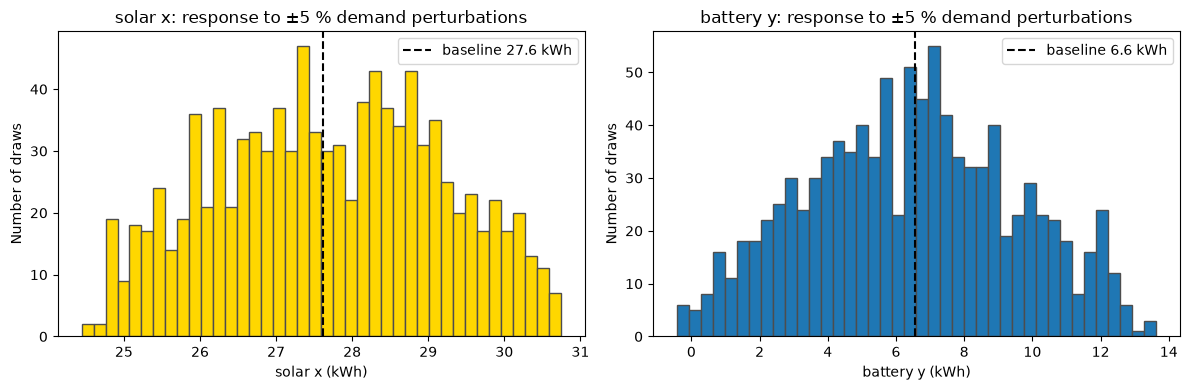

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k, name, color in zip(axes, [0, 1], ["solar x", "battery y"], ["gold", "tab:blue"]):
    ax.hist(S_mc[k], bins=40, color=color, edgecolor="0.3")
    ax.axvline(s_bar[k], color="k", ls="--", label=f"baseline {s_bar[k]:.1f} kWh")
    ax.set_xlabel(f"{name} (kWh)")
    ax.set_ylabel("Number of draws")
    ax.set_title(f"{name}: response to ±5 % demand perturbations")
    ax.legend()
fig.tight_layout()
plt.show()

Perturbing both demands by up to ±5 % moves solar modestly (95 % of draws between 25.0 and 30.3 kWh; largest change 11.5 %), but the battery swings widely, from 0.8 to 12.1 kWh, with changes of up to 108 %, and in 0.6 % of draws it would have to be negative. The largest observed amplification of relative error is 5.76, just below the condition number of 5.83, as the theory predicts; the bound is reached only for the worst-case direction of perturbation. The condition number describes the whole solution vector; component by component, the battery is much more sensitive because its value is small and is the difference of two large terms. For planning, the battery's daily requirement is the most uncertain quantity, so its capacity needs a generous margin.

## 10. Findings & Limitations

For the Kasese health centre, the dispatch model is well-posed (determinant −5, condition number 5.8), so each day's demands determine a unique solar–battery split that can be computed reliably, and solving all 30 days in one vectorised call is clearly faster than a loop. Solar does most of the work (about 28 kWh a day) and the battery supplies about 7 kWh, but the battery is by far the more volatile source (CV 41 % against 9 %) and, at three times the price, accounts for 42 % of the monthly cost of about UGX 213,000. Only one of the 30 simulated days was physically infeasible; non-negative least squares handled it with a smaller shortfall than clipping. The sensitivity analysis shows why the battery matters for planning: ±5 % demand uncertainty changes battery use by up to about 100 %, while solar moves by about 10 %. Adding a diesel generator keeps the system solvable, but at UGX 1,200/kWh it more than doubles the monthly cost, so it should be reserved for the night and emergency load it was added to cover.

These conclusions rest on strong assumptions. The constraint coefficients are given without physical justification, and the energy supplied (about 34 kWh a day) is much smaller than the stated loads, so the model is a stylised exercise rather than an engineering design. The demand data are simulated from an assumed weekly pattern with Gaussian noise, the tariffs and diesel cost are illustrative, and the model ignores battery capacity, state of charge, solar variability with weather and the timing of loads within the day. The diesel constraints were chosen here, and other plausible choices would change the hybrid results.